# 02 Exploratory Data Analysis
Reads the cleaned data and answers: which categories, regions, products and discount levels drive sales and profit

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

df_clean = pd.read_csv(
    "../data/cleaned/superstore_cleaned.csv",
    parse_dates=["Order Date", "Ship Date"],
    dtype={"Postal Code": str},
)
print(df_clean.shape)

(9993, 21)


In [2]:
sns.set_theme(style="whitegrid")       # clean chart background
plt.rcParams["figure.figsize"] = (10, 5)  # default chart size

In [3]:
total_sales = df_clean["Sales"].sum()
total_profit = df_clean["Profit"].sum()
total_orders = df_clean["Order ID"].nunique()   # distinct orders, not rows
profit_margin = total_profit / total_sales * 100

print(f"Total Sales:   ${total_sales:,.2f}")
print(f"Total Profit:  ${total_profit:,.2f}")
print(f"Total Orders:  {total_orders:,}")
print(f"Profit Margin: {profit_margin:.2f}%")

Total Sales:   $2,296,919.49
Total Profit:  $286,409.08
Total Orders:  5,009
Profit Margin: 12.47%


                     Sales     Profit  Margin %
Category                                       
Technology       836154.03  145454.95     17.40
Furniture        741718.42   18463.33      2.49
Office Supplies  719047.03  122490.80     17.04


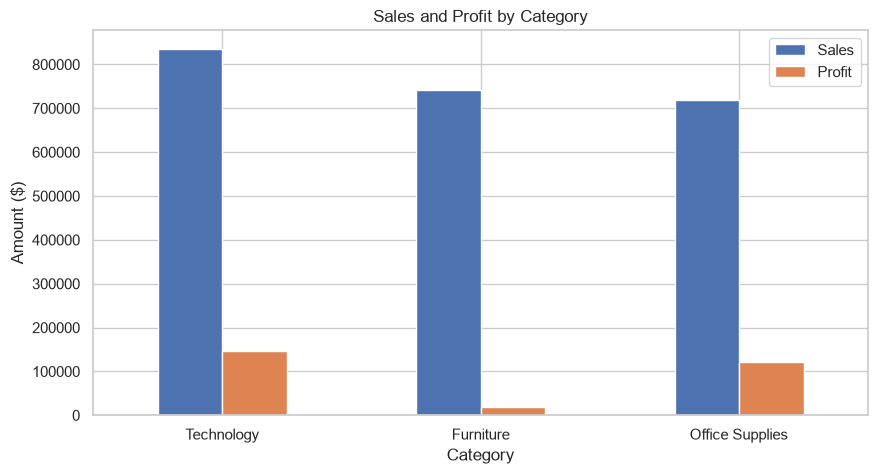

In [4]:
category = df_clean.groupby("Category")[["Sales", "Profit"]].sum()
category["Margin %"] = category["Profit"] / category["Sales"] * 100
category = category.sort_values("Sales", ascending=False)
print(category.round(2))

category[["Sales", "Profit"]].plot(kind="bar")
plt.title("Sales and Profit by Category")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)
plt.savefig("../images/sales_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

                  Sales    Profit  Margin %
Sub-Category                               
Tables        206965.53 -17725.48     -8.56
Bookcases     114880.00  -3472.56     -3.02
Supplies       46673.54  -1189.10     -2.55
Fasteners       3024.28    949.52     31.40
Machines      189238.63   3384.76      1.79
Labels         12486.31   5546.25     44.42
Art            27118.79   6527.79     24.07
Envelopes      16476.40   6964.18     42.27
Furnishings    91705.16  13059.14     14.24
Appliances    107532.16  18138.01     16.87
Storage       223843.61  21278.83      9.51
Chairs        328167.73  26602.23      8.11
Binders       203412.73  30221.76     14.86
Paper          78479.21  34053.57     43.39
Accessories   167380.32  41936.64     25.05
Phones        330007.05  44515.73     13.49
Copiers       149528.03  55617.82     37.20


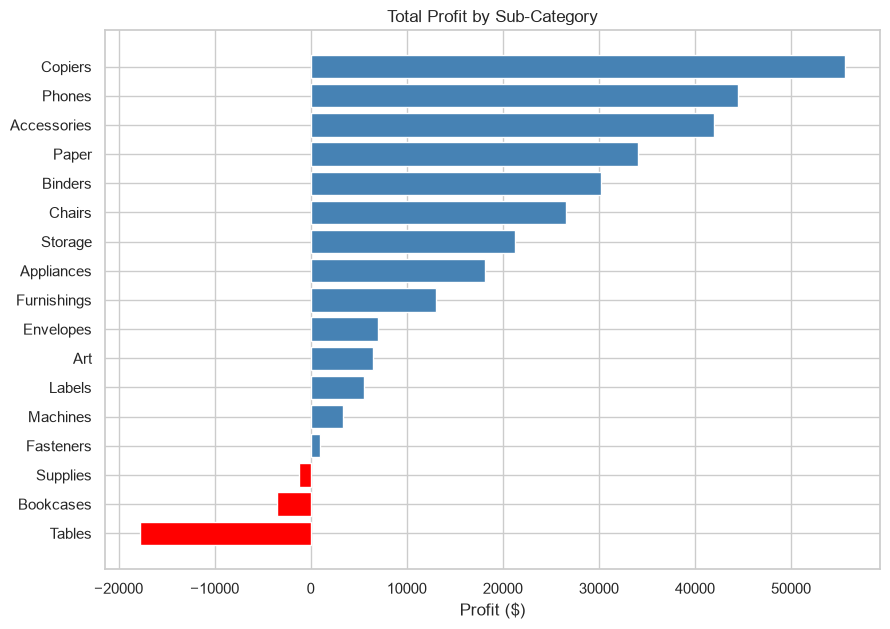

In [5]:
subcat = df_clean.groupby("Sub-Category")[["Sales", "Profit"]].sum()
subcat["Margin %"] = subcat["Profit"] / subcat["Sales"] * 100
subcat = subcat.sort_values("Profit")
print(subcat.round(2))

# Red bars for losses, blue for profits
colors = ["red" if p < 0 else "steelblue" for p in subcat["Profit"]]
plt.figure(figsize=(10, 7))
plt.barh(subcat.index, subcat["Profit"], color=colors)
plt.title("Total Profit by Sub-Category")
plt.xlabel("Profit ($)")
plt.savefig("../images/most_profitable_and_lossmaking_subcategories.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
product = df_clean.groupby("Product Name")[["Sales", "Profit"]].sum()

print("TOP 10 PRODUCTS BY SALES")
print(product.sort_values("Sales", ascending=False).head(10).round(2))

print("\nTOP 10 MOST PROFITABLE PRODUCTS")
print(product.sort_values("Profit", ascending=False).head(10).round(2))

print("\nTOP 10 LOSS-MAKING PRODUCTS")
print(product.sort_values("Profit").head(10).round(2))

TOP 10 PRODUCTS BY SALES
                                                       Sales    Profit
Product Name                                                          
Canon imageCLASS 2200 Advanced Copier               61599.82  25199.93
Fellowes PB500 Electric Punch Plastic Comb Bind...  27453.38   7753.04
Cisco TelePresence System EX90 Videoconferencin...  22638.48  -1811.08
HON 5400 Series Task Chairs for Big and Tall        21870.58      0.00
GBC DocuBind TL300 Electric Binding System          19823.48   2233.51
GBC Ibimaster 500 Manual ProClick Binding System    19024.50    760.98
Hewlett Packard LaserJet 3310 Copier                18839.69   6983.88
HP Designjet T520 Inkjet Large Format Printer -...  18374.90   4094.98
GBC DocuBind P400 Electric Binding System           17965.07  -1878.17
High Speed Automatic Electric Letter Opener         17030.31   -262.00

TOP 10 MOST PROFITABLE PRODUCTS
                                                       Sales    Profit
Product Name       

             Sales     Profit  Margin %
Region                                 
West     725457.82  108418.45     14.94
East     678499.87   91534.84     13.49
South    391721.90   46749.43     11.93
Central  501239.89   39706.36      7.92


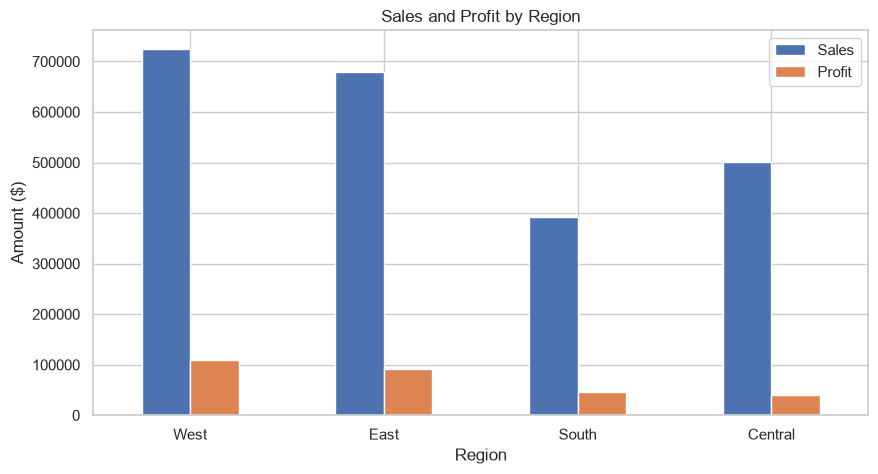

In [7]:
region = df_clean.groupby("Region")[["Sales", "Profit"]].sum()
region["Margin %"] = region["Profit"] / region["Sales"] * 100
region = region.sort_values("Profit", ascending=False)
print(region.round(2))

region[["Sales", "Profit"]].plot(kind="bar")
plt.title("Sales and Profit by Region")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)
plt.savefig("../images/sales_by_region.png", dpi=150, bbox_inches="tight")
plt.show()

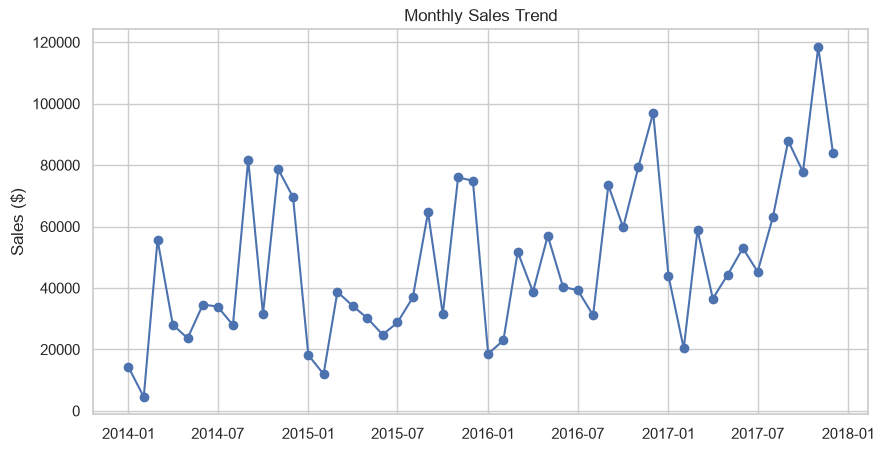

          Sales    Profit  Margin %  Sales Growth %
Year                                               
2014  483966.13  49556.03     10.24             NaN
2015  470532.51  61618.60     13.10           -2.78
2016  609205.60  81795.17     13.43           29.47
2017  733215.26  93439.27     12.74           20.36


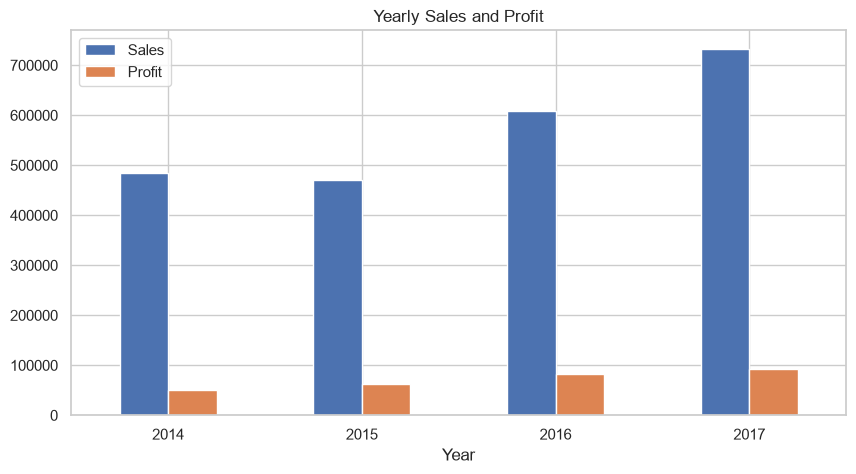

In [8]:
# Create Year and Month-period columns from the Order Date
df_clean["Year"] = df_clean["Order Date"].dt.year
df_clean["YearMonth"] = df_clean["Order Date"].dt.to_period("M")

# Monthly sales
monthly = df_clean.groupby("YearMonth")["Sales"].sum()
monthly.index = monthly.index.to_timestamp()   # makes the x-axis plot correctly

plt.plot(monthly.index, monthly.values, marker="o")
plt.title("Monthly Sales Trend")
plt.ylabel("Sales ($)")
plt.show()

# Yearly sales, profit, and margin
yearly = df_clean.groupby("Year")[["Sales", "Profit"]].sum()
yearly["Margin %"] = yearly["Profit"] / yearly["Sales"] * 100
yearly["Sales Growth %"] = yearly["Sales"].pct_change() * 100
print(yearly.round(2))

yearly[["Sales", "Profit"]].plot(kind="bar")
plt.title("Yearly Sales and Profit")
plt.xticks(rotation=0)
plt.savefig("../images/sales_by_month_and_year.png", dpi=150, bbox_inches="tight")
plt.show()

          Rows  Total_Profit  Avg_Profit
Discount                                
0.00      4798     320987.60       66.90
0.10        94       9029.18       96.06
0.15        52       1418.99       27.29
0.20      3657      90337.31       24.70
0.30       226     -10357.22      -45.83
0.32        27      -2391.14      -88.56
0.40       206     -23057.05     -111.93
0.45        11      -2493.11     -226.65
0.50        66     -20506.43     -310.70
0.60       138      -5944.66      -43.08
0.70       418     -40075.36      -95.87
0.80       300     -30539.04     -101.80


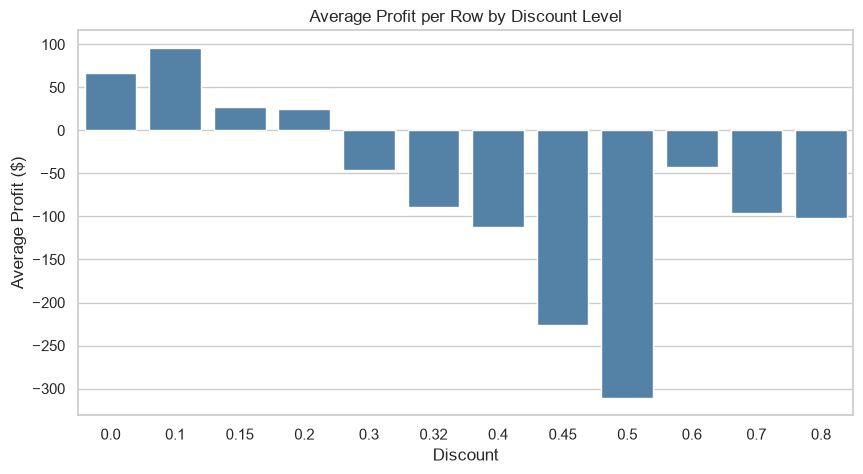

Correlation (Discount vs Profit): -0.219


In [9]:
# Group by each discount level
discount = df_clean.groupby("Discount").agg(
    Rows=("Profit", "count"),
    Total_Profit=("Profit", "sum"),
    Avg_Profit=("Profit", "mean"),
)
print(discount.round(2))

plt.figure(figsize=(10, 5))
sns.barplot(x=discount.index, y=discount["Avg_Profit"], color="steelblue")
plt.title("Average Profit per Row by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Average Profit ($)")
plt.savefig("../images/sales_by_discount.png", dpi=150, bbox_inches="tight")
plt.show()

print("Correlation (Discount vs Profit):",
      round(df_clean["Discount"].corr(df_clean["Profit"]), 3))

## Business Insights

**1. Deep discounts are erasing profit**
- Data: Rows with a discount of 30% or more (13.9% of rows) lost $135,364 in total, while rows at 20% or less earned $421,773. Average profit per row falls from $66.90 at 0% discount to $24.70 at 20%, and is negative from 30%.
- Why it matters: Heavy discounts give back a large share of the profit that normal sales produce.
- Action: Review or cap discounts above 20%, and test it on one category first while watching sales volume.

**2. Furniture sells a lot but earns very little**
- Data: Furniture is 32.3% of sales but only 6.4% of profit (margin 2.49%, against about 17% for Technology and Office Supplies). It has the highest average discount of the three categories (0.174).
- Why it matters: A third of revenue produces a small fraction of profit.
- Action: Review Furniture pricing and discount policy first.

**3. Tables and Bookcases lose money and are heavily discounted**
- Data: Tables lose $17,725 and Bookcases lose $3,473. They have the 3rd and 4th highest average discounts of 17 sub-categories (0.261 and 0.211). Supplies also loses $1,189, but its discount is low (0.077), so discounts do not explain it.
- Why it matters: These products pull down the whole Furniture category.
- Action: Reduce discounts on Tables and Bookcases, and investigate cost and pricing for Supplies.

**4. Central region has the weakest margin and the heaviest discounting**
- Data: Central has the lowest margin (7.92%) and the highest average discount (0.240), with 27.7% of rows at 30% or more, against 3.7% in West, which has the highest margin (14.94%). Seven of the 17 sub-categories lose money in Central (about -$15,294 combined), including Furnishings, Appliances, Machines and Binders, which are profitable across all regions together.
- Why it matters: Central's weakness is broad, not limited to a few problem products.
- Action: Review Central's discount and pricing practices across product lines, starting with Furnishings and Tables, its two largest losses.

**5. Sales and profit grew, but the 2017 margin slipped**
- Data: Sales grew 51.5% and profit 88.6% from 2014 to 2017. The margin rose from 10.24% to 13.43% by 2016, then fell to 12.74% in 2017.
- Why it matters: If the margin keeps falling, profit will grow more slowly than sales.
- Action: Monitor the margin regularly and look at what changed in 2017.

**6. Top-selling products are not always profitable**
- Data: Among the top 10 products by sales, the Cisco TelePresence system (-$1,811), GBC DocuBind P400 (-$1,878) and the electric letter opener (-$262) lose money, and the HON 5400 chairs break even. The Canon imageCLASS copier earns $25,200 on $61,600 of sales.
- Why it matters: Ranking products only by sales hides losses.
- Action: Track profit per product next to sales, and review the loss-making best sellers.

**7. Technology and Office Supplies carry the profit**
- Data: Technology is 36.4% of sales but 50.8% of profit, and Office Supplies is 31.3% of sales but 42.8% of profit. Copiers have a 37.20% margin.
- Why it matters: Profit is concentrated in these categories.
- Action: Protect and promote high-margin lines.

**8. Consumer is the largest segment but has the lowest margin**
- Data: Consumer makes 50.6% of sales and 46.8% of profit (margin 11.55%). Home Office is the smallest segment (18.7% of sales) but has the highest margin (14.05%). Corporate sits in between (13.03%).
- Why it matters: Growth in Consumer adds the most revenue, but each dollar of Consumer sales earns slightly less profit than in the other segments.
- Action: Check discount levels by segment to see whether they explain the gap, and consider promoting Home Office